# 92104 (North Park) – Reentrant Corners

A **reentrant corner** is a concave corner of a building footprint: an inside corner where the outline turns back in (like the inside of an L). In a wildfire, wind swirls into these corners and embers pile up there, so they're a known weak point.

Goal: use spatial SQL (DuckDB) to find every concave vertex of every footprint in 92104, plot them on the buildings, and (extra credit) measure how *deep* each concave notch is.

Uses the footprints from the previous homework (`python src/data/fetch_osm.py --zip 92104`), which are in UTM 11N, so all distances are in meters.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import duckdb
from pathlib import Path

ZIP = "92104"
RAW = Path("../../data/raw")
gdf = gpd.read_parquet(RAW / f"osm_buildings_{ZIP}.parquet")
zcta = gpd.read_parquet(RAW / f"zcta_{ZIP}.parquet")

con = duckdb.connect()
con.execute("INSTALL spatial; LOAD spatial;")

# same table name the assignment uses; bid = unique row id per building
con.execute(f"""
    CREATE OR REPLACE TABLE SanDiegoStructures AS
    SELECT ROW_NUMBER() OVER () AS bid, id AS osm_id, building, geometry::GEOMETRY AS geom
    FROM '{RAW}/osm_buildings_{ZIP}.parquet'
""")
print("buildings:", con.execute("SELECT COUNT(*) FROM SanDiegoStructures").fetchall()[0][0])

/opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


buildings: 10826


## The query

Each step is one CTE:

1. **`structs`**: the buildings to work on. While testing, this is one building (`WHERE bid = ...`) or a few (`LIMIT 5`); for the real run it's all of them.
2. **`polys`**: some footprints are multipolygons, so `ST_Dump` splits them into single polygons (`part`).
3. **`rings`**: the outer boundary of each polygon (`ST_ExteriorRing`), with repeated points removed.
4. **`verts`**: one row per vertex with its x, y and its position `idx` in the order the outline is drawn. A ring repeats its first point at the end, so we only keep the first `n = NPoints − 1`.
5. **`orient`**: whether the outline is drawn counterclockwise or clockwise, from the sign of its area (shoelace formula, by joining each vertex to the next one). This matters because "is this corner concave" flips depending on which way you walk around the shape.
6. **`triples`**: joins every vertex to the one before and after it (`idx − 1`, `idx + 1`). The first vertex's previous one is the last vertex, and the last vertex's next one is the first: that's the edge case the hint mentions. For each corner it computes the **cross product** (which way it turns) and **dot product** of the two edges.
7. **`angles`**: the **interior angle** at each vertex in degrees. Below 180° = a normal (convex) corner; **above 180° = concave (reentrant)**.
8. **Final select**: keep corners with interior angle > 185°. The 5° margin skips points that are almost straight (lines that were traced with a tiny wobble). It also measures the **depth** of each concave corner (extra credit, see below).

**About `ST_Angle`:** BigQuery has `ST_ANGLE(p1, p2, p3)`, which returns the clockwise angle at `p2`. DuckDB doesn't have it, so the interior angle is computed from the cross and dot products with `atan2`, which is the same angle. In BigQuery the `triples` + `angles` CTEs would be one line: `ST_ANGLE(prev_pt, pt, next_pt)`, flipped to `2π − angle` for outlines drawn the other way.

In [2]:
def reentrant_corners(subset_sql, min_interior=185):
    """Concave vertices for the buildings picked by subset_sql (a SELECT on SanDiegoStructures)."""
    return con.execute(f"""
    WITH structs AS (
        {subset_sql}
    ),
    polys AS (
        SELECT bid, unnest(ST_Dump(geom)).geom AS poly FROM structs
    ),
    rings AS (
        SELECT bid, ROW_NUMBER() OVER (PARTITION BY bid) AS part,
               ST_RemoveRepeatedPoints(ST_ExteriorRing(poly)) AS ring
        FROM polys
        WHERE ST_GeometryType(poly) = 'POLYGON'
    ),
    verts AS (
        SELECT bid, part, i AS idx, ST_NPoints(ring) - 1 AS n,
               ST_X(ST_PointN(ring, i::INTEGER)) AS x,
               ST_Y(ST_PointN(ring, i::INTEGER)) AS y
        FROM rings, generate_series(1, ST_NPoints(ring) - 1) AS t(i)
    ),
    orient AS (   -- shoelace: > 0 means drawn counterclockwise
        SELECT v.bid, v.part, SUM(v.x * w.y - w.x * v.y) / 2 AS signed_area
        FROM verts v
        JOIN verts w ON w.bid = v.bid AND w.part = v.part
                    AND w.idx = CASE WHEN v.idx = v.n THEN 1 ELSE v.idx + 1 END
        GROUP BY v.bid, v.part
    ),
    triples AS (  -- each vertex b with the vertex before (a) and after (c)
        SELECT b.bid, b.part, b.idx, b.x, b.y,
               (b.x - a.x) * (c.y - b.y) - (b.y - a.y) * (c.x - b.x) AS cross,
               (b.x - a.x) * (c.x - b.x) + (b.y - a.y) * (c.y - b.y) AS dot
        FROM verts b
        JOIN verts a ON a.bid = b.bid AND a.part = b.part
                    AND a.idx = CASE WHEN b.idx = 1 THEN b.n ELSE b.idx - 1 END
        JOIN verts c ON c.bid = b.bid AND c.part = b.part
                    AND c.idx = CASE WHEN b.idx = b.n THEN 1 ELSE b.idx + 1 END
    ),
    angles AS (   -- interior angle: 180 minus the turn, turn measured for the ring's direction
        SELECT t.*, 180 - degrees(atan2(t.cross, t.dot)) * sign(o.signed_area) AS interior_deg
        FROM triples t JOIN orient o USING (bid, part)
    )
    SELECT a.bid, a.part, a.idx, a.x, a.y,
           ROUND(a.interior_deg, 1) AS interior_deg,
           -- extra credit: how far the corner sits inside the shape's convex hull
           ST_Distance(ST_Point(a.x, a.y), ST_ExteriorRing(ST_ConvexHull(r.ring))) AS depth_m
    FROM angles a JOIN rings r USING (bid, part)
    WHERE a.interior_deg > {min_interior}
    ORDER BY a.bid, a.part, a.idx
    """).df()

### Test first on shapes where we know the answer

An L-shape drawn counterclockwise, the same L drawn clockwise, and a square. Both L's should give exactly one concave corner at (1, 1) with a 270° interior angle, and the square should give none.

In [3]:
con.execute("""
    CREATE OR REPLACE TABLE toy AS
    SELECT 1 AS bid, ST_GeomFromText('POLYGON((0 0, 2 0, 2 1, 1 1, 1 2, 0 2, 0 0))') AS geom   -- L, counterclockwise
    UNION ALL SELECT 2, ST_GeomFromText('POLYGON((0 0, 0 2, 1 2, 1 1, 2 1, 2 0, 0 0))')       -- L, clockwise
    UNION ALL SELECT 3, ST_GeomFromText('POLYGON((0 0, 4 0, 4 4, 0 4, 0 0))')                 -- square
""")
reentrant_corners("SELECT * FROM toy")

,bid,part,idx,x,y,interior_deg,depth_m
0,1,1,4,1.0,1.0,270.0,0.707107
1,2,1,4,1.0,1.0,270.0,0.707107


### Then one real building

(Here the `structs` CTE is limited to the first real building that has a concave corner, as the assignment suggests, before running everything.)

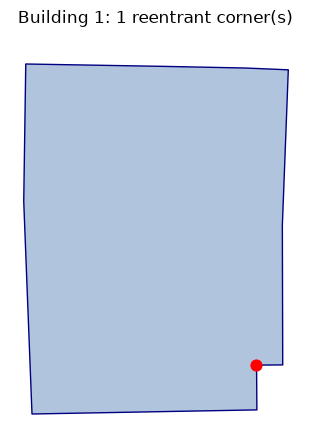

,bid,part,idx,x,y,interior_deg,depth_m
0,1,1,9,487348.269778,3.623383e+06,270.0,1.140572


In [4]:
one = con.execute("SELECT bid FROM SanDiegoStructures WHERE ST_NPoints(geom) >= 9 ORDER BY bid LIMIT 1").fetchall()[0][0]
test = reentrant_corners(f"SELECT * FROM SanDiegoStructures WHERE bid = {one}")
b = gdf.iloc[[one - 1]]

fig, ax = plt.subplots(figsize=(5, 5))
b.plot(ax=ax, color="lightsteelblue", edgecolor="navy")
ax.scatter(test.x, test.y, color="red", s=60, zorder=3)
ax.set_title(f"Building {one}: {len(test)} reentrant corner(s)")
ax.set_axis_off()
plt.show()
test

## Run on all of 92104

In [5]:
corners = reentrant_corners("SELECT * FROM SanDiegoStructures")
n_bld = con.execute("SELECT COUNT(*) FROM SanDiegoStructures").fetchall()[0][0]
per_bld = corners.groupby("bid").size()

print(f"reentrant corners: {len(corners):,}")
print(f"buildings with at least one: {per_bld.size:,} of {n_bld:,} ({100 * per_bld.size / n_bld:.1f}%)")
print("\ninterior angle of the concave corners (degrees):")
print(corners["interior_deg"].describe().round(1))
counts = per_bld.reindex(range(1, n_bld + 1), fill_value=0).clip(upper=6).value_counts().sort_index()
counts.index = [str(i) if i < 6 else "6+" for i in counts.index]
counts.rename("buildings").to_frame()

reentrant corners: 13,856
buildings with at least one: 4,815 of 10,826 (44.5%)

interior angle of the concave corners (degrees):
count    13856.0
mean       269.2
std          6.6
min        185.7
25%        269.8
50%        270.0
75%        270.1
max        331.1
Name: interior_deg, dtype: float64


,buildings
0,6011
1,1768
2,1184
3,549
4,523
5,236
6+,555


**Observations**
- 13,790 reentrant corners, and 44% of buildings have at least one. So almost half of North Park's footprints are not simple boxes.
- 97% of the concave corners are between 260° and 280°, i.e. right-angle inside corners: L-shapes, T-shapes, bump-outs and porches. Only 26 are under 200° (outlines that were traced with a slight wobble) and 15 are over 300° (sharp spikes).
- Most buildings with corners have only 1–2. The 550 with 6 or more are mostly bigger, more complex buildings like apartment blocks.

## Figure: reentrant corners on the buildings

Same 250 m window near the middle of the zip as the footprint homework. Red dots are the concave corners.

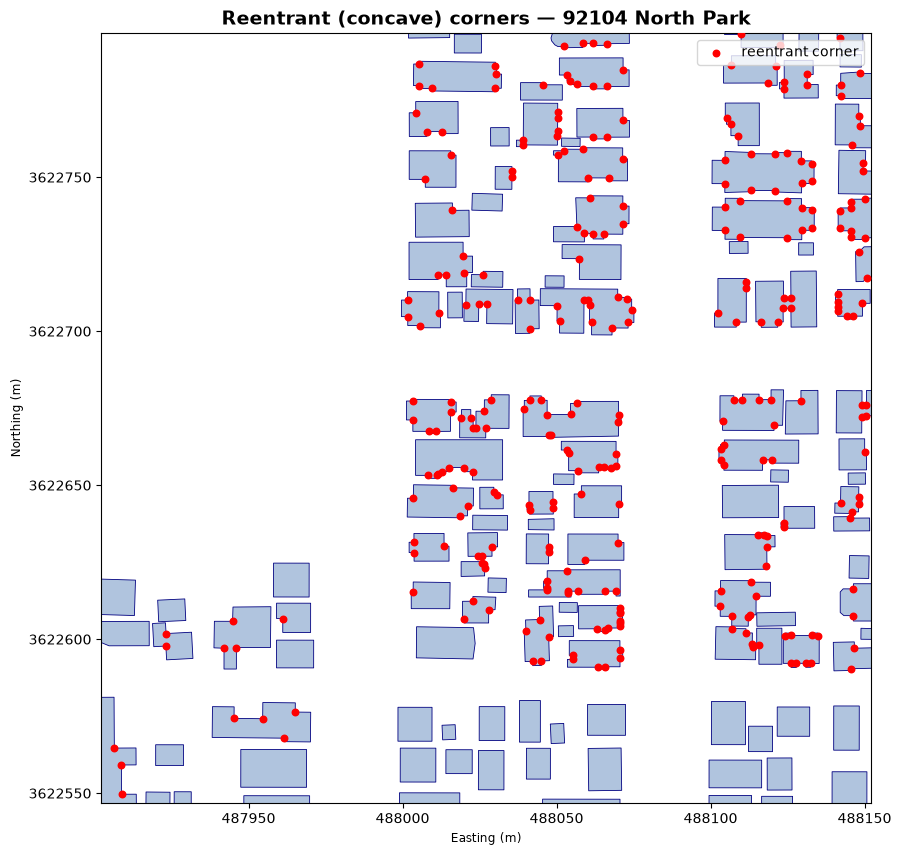

In [6]:
near = gdf.distance(zcta.geometry.iloc[0].centroid).idxmin()
cx, cy = gdf.loc[near].geometry.centroid.coords[0]
half = 125
in_win = corners[(corners.x.between(cx - half, cx + half)) & (corners.y.between(cy - half, cy + half))]

fig, ax = plt.subplots(figsize=(10, 10))
gdf.plot(ax=ax, color="lightsteelblue", edgecolor="navy", linewidth=0.6)
ax.scatter(in_win.x, in_win.y, color="red", s=22, zorder=3, label="reentrant corner")
ax.set_xlim(cx - half, cx + half)
ax.set_ylim(cy - half, cy + half)
ax.ticklabel_format(useOffset=False, style="plain")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_title(f"Reentrant (concave) corners — {ZIP} North Park", fontsize=14, fontweight="bold")
ax.legend(loc="upper right")
plt.show()

Close-ups of six buildings from that window with the most concave corners, each corner labelled with its depth (extra credit, below).

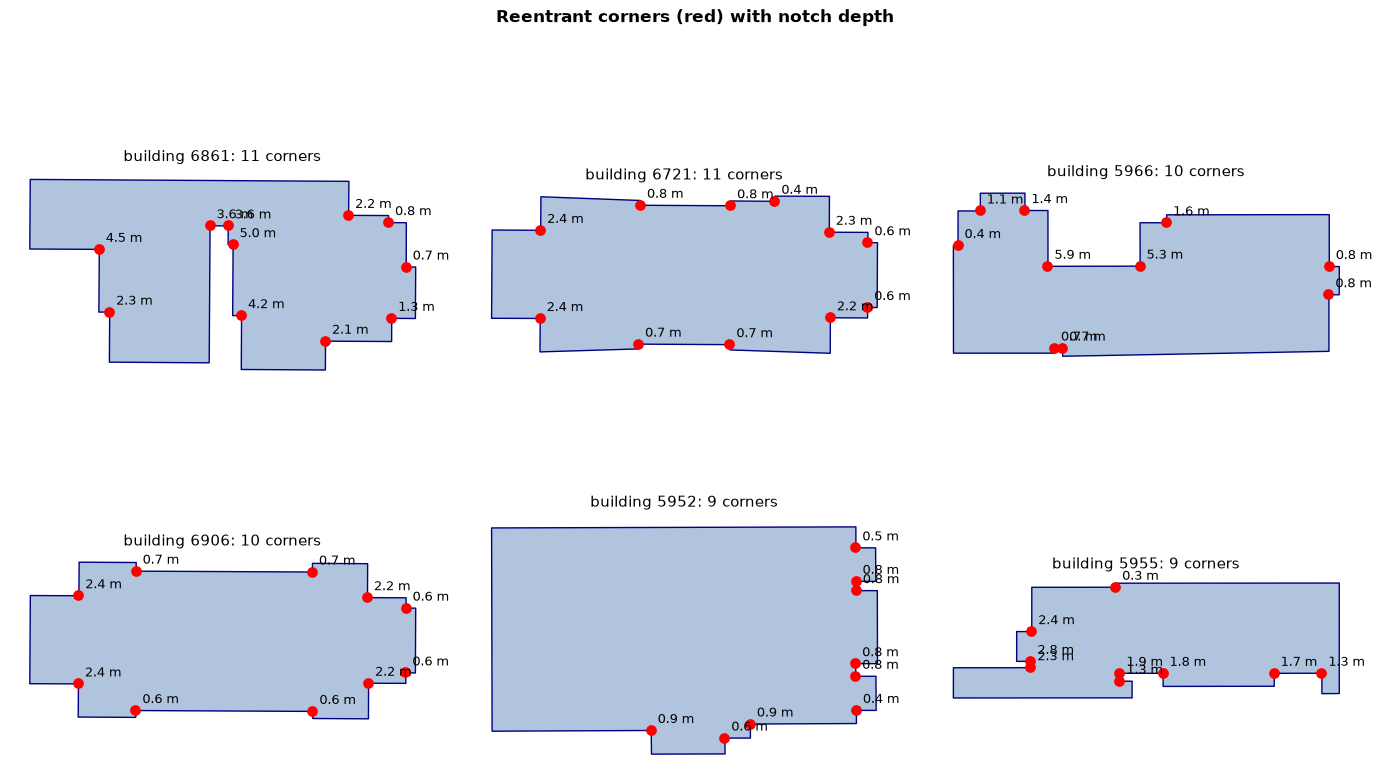

In [7]:
win_ids = in_win.groupby("bid").size().sort_values(ascending=False).head(6).index

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, bid in zip(axes.flat, win_ids):
    pts = corners[corners.bid == bid]
    gdf.iloc[[bid - 1]].plot(ax=ax, color="lightsteelblue", edgecolor="navy")
    ax.scatter(pts.x, pts.y, color="red", s=45, zorder=3)
    for _, p in pts.iterrows():
        ax.annotate(f"{p.depth_m:.1f} m", (p.x, p.y), textcoords="offset points", xytext=(5, 5), fontsize=9)
    ax.set_title(f"building {bid}: {len(pts)} corners", fontsize=11)
    ax.set_axis_off()
fig.suptitle("Reentrant corners (red) with notch depth", fontweight="bold")
plt.tight_layout()
plt.show()

## Extra credit: how deep is the notch? 6 inches or 6 feet?

The interior angle says a corner is concave, but not *how much* it matters. A 6-inch jog in a wall is a tracing wobble; a 6-foot inside corner is a real ember trap.

**Method:** wrap each footprint in its **convex hull** (the shape you'd get stretching a rubber band around it). A convex corner sits on the hull; a concave corner sits inside it. The **distance from the concave corner to the hull's edge** is how far the notch cuts into the building. That's `depth_m` in the query above (`ST_Distance` to `ST_ExteriorRing(ST_ConvexHull(...))`).

6 inches ≈ 0.15 m, 6 feet ≈ 1.83 m.

In [8]:
bins = [0, 0.15, 0.5, 1.83, np.inf]
labels = ["< 6 in (0.15 m)", "6 in – 0.5 m", "0.5 m – 6 ft", "> 6 ft (1.83 m)"]

summary = (corners.depth_m.groupby(np.digitize(corners.depth_m, bins[1:-1])).size()
           .rename(index=dict(enumerate(labels))).rename("corners").to_frame())
summary["pct"] = (100 * summary.corners / summary.corners.sum()).round(1)
print("median depth:", round(corners.depth_m.median(), 2), "m")
summary

median depth: 1.45 m


,corners,pct
< 6 in (0.15 m),4,0.0
6 in – 0.5 m,1080,7.8
0.5 m – 6 ft,7102,51.3
> 6 ft (1.83 m),5670,40.9


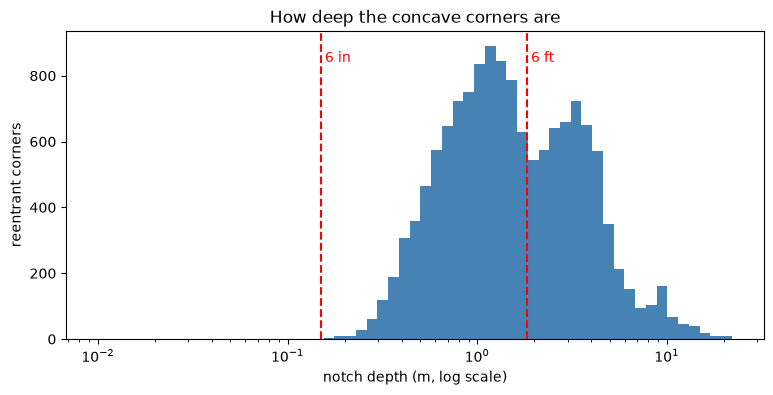

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(corners.depth_m.clip(lower=0.01), bins=np.logspace(-2, np.log10(corners.depth_m.max()), 60), color="steelblue")
ax.set_xscale("log")
for d, lab in [(0.15, "6 in"), (1.83, "6 ft")]:
    ax.axvline(d, color="red", linestyle="--")
    ax.text(d * 1.05, ax.get_ylim()[1] * 0.9, lab, color="red")
ax.set_xlabel("notch depth (m, log scale)")
ax.set_ylabel("reentrant corners")
ax.set_title("How deep the concave corners are")
plt.show()

**Observations**
- The median notch is about 1.45 m deep, so most of these are real features of the building, not tracing noise.
- Only 4 corners are under 6 inches, and about 8% are between 6 inches and 0.5 m. Those small jogs could be real (a bay window, a chimney) or a slightly wobbly tracing, and a filter like "depth > 0.5 m" would remove most of them.
- 41% of concave corners are deeper than 6 feet. Those are the inside corners where embers would actually pile up, so for wildfire risk they matter much more than the shallow ones.
- Limitation: the hull distance measures how far the corner sits *inside the overall shape*. For a long, narrow notch, the corner at its opening gets a small depth even though the notch is deep. Measuring each notch as a separate shape (convex hull minus the footprint, then the size of each leftover piece) would fix that.